# Modelos próprios: PyTorch, TensorFlow/Keras e outras bibliotecas

Você monta o modelo fora da AutoHybTS, diz qual versão da biblioteca ele exige e o **registra** no experimento. A partir daí ele é usado **pelo nome** em tudo: `create_model`, busca (`base_models`), corretor de híbridos (`correctors`), estágios, decomposição, combinação, `tune_model`, finalização e persistência — com as mesmas regras de validação temporal sem vazamento.

| Caminho | Para quê |
|---|---|
| `torch_model(Modulo, ...)` | um `torch.nn.Module` seu (ou do zoo: LSTM, Transformer, Mamba) |
| `keras_model(builder, ...)` | uma função que monta um `keras.Model` (TensorFlow 2.16+/Keras 3) |
| `CustomForecaster(fit_fn, predict_fn)` | qualquer biblioteca, por duas funções |
| `RegressorForecaster(estimador)` | qualquer regressor com `fit`/`predict` (LightGBM, XGBoost, scikit-learn) |

O wrapper cuida das janelas de lags, da diferenciação e padronização **ajustadas só no treino de cada origem** (a padronização usa só as linhas de treino interno, sem a cauda da parada antecipada), do treino (Adam, parada antecipada numa cauda interna do treino), da semente e da previsão recursiva com pesos congelados. Em séries com tendência forte, use `differencing=1`.

Instalação: `pip install "autohybts[torch]"` e/ou `pip install "autohybts[tensorflow]"`. Este notebook é pesado e é versionado com as saídas.

**GPU.** As redes PyTorch usam `device="auto"`: GPU CUDA quando há uma (instale a build do PyTorch com CUDA, por exemplo `pip install torch --index-url https://download.pytorch.org/whl/cu130`), CPU caso contrário. O TensorFlow não usa GPU no Windows nativo desde a versão 2.11 (só via WSL2); aqui as redes Keras rodam na CPU.

In [1]:
import os
import time
import warnings

import pandas as pd

import autohybts
from autohybts.models import framework_versions

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # antes de importar o TensorFlow
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
print("AutoHybTS", autohybts.__version__)
framework_versions(["torch", "tensorflow", "keras", "sklearn", "statsmodels"])

AutoHybTS 0.0.1


{'keras': '3.15.1',
 'sklearn': '1.9.1',
 'statsmodels': '0.15.0',
 'tensorflow': '2.21.0',
 'torch': '2.14.1+cu130'}

## 1. Os modelos

### PyTorch: do zoo e um módulo escrito aqui

O contrato do módulo: o construtor recebe `n_inputs` (número de lags) e os seus argumentos; o `forward` recebe um tensor `(batch, n_inputs)` com os lags **do mais antigo ao mais recente** e devolve `(batch,)`.

`MambaNet` é um bloco de espaço de estados seletivo no estilo Mamba (Gu e Dao, 2023) em PyTorch puro; o pacote otimizado `mamba-ssm` exige CUDA no Linux.

In [2]:
import torch
from torch import nn

from autohybts.models import torch_model
from autohybts.models.torch_zoo import LSTMNet, MambaNet, TransformerNet


class GRUNet(nn.Module):
    """Um modelo próprio: GRU sobre os lags, cabeça linear no último passo."""

    def __init__(self, n_inputs: int, hidden: int = 16) -> None:
        super().__init__()
        self.gru = nn.GRU(1, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.gru(x.unsqueeze(-1))
        return self.head(out[:, -1]).squeeze(-1)


TRAIN = dict(lags=14, differencing=1, epochs=60, patience=8, device="auto")
print(
    "PyTorch",
    torch.__version__,
    "| GPU:",
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "nenhuma (CPU)",
)
torch_models = {
    "torch_lstm": torch_model(LSTMNet, hidden=16, **TRAIN),
    "torch_transformer": torch_model(TransformerNet, d_model=16, heads=2, layers=1, **TRAIN),
    "torch_mamba": torch_model(MambaNet, d_model=16, d_state=8, layers=1, **TRAIN),
    "torch_gru": torch_model(GRUNet, hidden=16, **TRAIN),
}

PyTorch 2.14.1+cu130 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU


### TensorFlow/Keras: do zoo e um builder escrito aqui

O builder é chamado como `builder(n_inputs=..., **parâmetros)` e devolve um `keras.Model` **não compilado** de `(batch, n_inputs)` para `(batch, 1)`.

In [3]:
import keras

from autohybts.models import keras_model, keras_zoo


def conv_net(n_inputs: int, filters: int = 16) -> keras.Model:
    """Um builder próprio: convolução causal 1D sobre os lags."""

    inputs = keras.Input(shape=(n_inputs,))
    h = keras.layers.Reshape((n_inputs, 1))(inputs)
    h = keras.layers.Conv1D(filters, 3, padding="causal", activation="relu")(h)
    h = keras.layers.GlobalAveragePooling1D()(h)
    return keras.Model(inputs, keras.layers.Dense(1)(h))


keras_models = {
    "keras_lstm": keras_model(keras_zoo.lstm, units=16, **TRAIN),
    "keras_transformer": keras_model(keras_zoo.transformer, d_model=16, heads=2, layers=1, **TRAIN),
    "keras_conv": keras_model(conv_net, filters=16, **TRAIN),
}

### Outra biblioteca por duas funções, e um regressor qualquer

`CustomForecaster`: `fit_fn(y, **params)` devolve um estado; `predict_fn(estado, horizonte, histórico, **params)` devolve as previsões. Aqui, a suavização exponencial de Holt-Winters do statsmodels. `RegressorForecaster` põe qualquer `fit`/`predict` sobre os lags (aqui, gradient boosting do scikit-learn; LightGBM ou XGBoost entram igual).

In [4]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor

from autohybts.models import CustomForecaster, RegressorForecaster


def holt_winters_fit(y, seasonal_periods=7):
    from statsmodels.tsa.holtwinters import ExponentialSmoothing

    model = ExponentialSmoothing(y, trend="add", seasonal="add", seasonal_periods=seasonal_periods)
    return model.fit()


def holt_winters_predict(fitted, horizon, history, seasonal_periods=7):
    # Parâmetros congelados; um contexto mais longo reaplica o filtro sem reajustar.
    if len(history) > len(fitted.model.endog):
        from statsmodels.tsa.holtwinters import ExponentialSmoothing

        model = ExponentialSmoothing(
            history, trend="add", seasonal="add", seasonal_periods=seasonal_periods
        )
        fitted = model.fit(
            **{
                "smoothing_level": fitted.params["smoothing_level"],
                "smoothing_trend": fitted.params["smoothing_trend"],
                "smoothing_seasonal": fitted.params["smoothing_seasonal"],
                "optimized": False,
            }
        )
    return np.asarray(fitted.forecast(horizon))


other_models = {
    "holt_winters": lambda p: CustomForecaster(
        holt_winters_fit, holt_winters_predict, params=dict(p), min_train_size=21
    ),
    "hist_gbm": RegressorForecaster(HistGradientBoostingRegressor(max_iter=200), lags=14),
}

## 2. Registrar no experimento

`requires` diz a versão exigida (conferida quando o modelo é construído); `version` identifica a registração (entra na chave de cada tentativa: mude quando mudar o código do modelo). A família define em que ponto da cadeia incremental o modelo desafia o campeão.

In [5]:
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data

y = get_data("synthetic_daily", n=500)


def register(experiment):
    # Registra todos os modelos externos num experimento.

    for name, factory in torch_models.items():
        experiment.register_model(
            name, factory, family="deep", requires={"torch": ">=2.2"}, version="1"
        )
    for name, factory in keras_models.items():
        experiment.register_model(
            name, factory, family="deep", requires={"tensorflow": ">=2.16"}, version="1"
        )
    experiment.register_model(
        "holt_winters",
        other_models["holt_winters"],
        family="statistical",
        requires={"statsmodels": ">=0.14"},
        version="1",
    )
    experiment.register_model("hist_gbm", other_models["hist_gbm"], family="tree", version="1")
    # Também como corretores de resíduos: a mesma ideia, na janela de resíduos.
    experiment.register_model(
        "torch_lstm_corr",
        torch_model(LSTMNet, kind="corrector", hidden=8, epochs=60, device="auto"),
        kind="corrector",
        requires={"torch": ">=2.2"},
        version="1",
    )
    experiment.register_model(
        "keras_mlp_corr",
        keras_model(keras_zoo.mlp, kind="corrector", hidden=[16], epochs=60),
        kind="corrector",
        requires={"tensorflow": ">=2.16"},
        version="1",
    )
    return experiment


exp = register(AutoHybridExperiment(fh=14, session_id=42, fold=2))
exp.fit(y)
exp.models().query("version.notna()")[["family", "requires", "version"]]

family           requires version
kind      name                                                     
base      hist_gbm                  tree                NaN       1
          holt_winters       statistical  statsmodels>=0.14       1
          keras_conv                deep   tensorflow>=2.16       1
          keras_lstm                deep   tensorflow>=2.16       1
          keras_transformer         deep   tensorflow>=2.16       1
          torch_gru                 deep         torch>=2.2       1
          torch_lstm                deep         torch>=2.2       1
          torch_mamba               deep         torch>=2.2       1
          torch_transformer         deep         torch>=2.2       1
corrector keras_mlp_corr       corrector   tensorflow>=2.16       1
          torch_lstm_corr      corrector         torch>=2.2       1

## 3. Cada modelo nas mesmas origens

In [6]:
rows = []
for name in ["linear", "seasonal_naive", *torch_models, *keras_models, "holt_winters", "hist_gbm"]:
    started = time.perf_counter()
    result = exp.create_model(name)
    frame = result.evaluation.to_frame().groupby("layer")["MASE"].mean()
    rows.append(
        {
            "modelo": name,
            "MASE V_search": frame["search"],
            "MASE V_select": frame["select"],
            "segundos": time.perf_counter() - started,
        }
    )
pd.DataFrame(rows).set_index("modelo").round(3).sort_values("MASE V_select")

,MASE V_search,MASE V_select,segundos
modelo,,,
holt_winters,0.662,0.966,5.181
torch_gru,0.747,1.014,46.740
torch_transformer,1.041,1.193,83.970
linear,0.899,1.289,0.273
seasonal_naive,1.133,1.513,0.023
hist_gbm,1.467,1.548,4692.482
torch_lstm,1.025,1.600,52.860
torch_mamba,0.844,1.608,97.202
keras_lstm,NaN,NaN,0.098


### Validação interna de cada rede

Em cada origem, as últimas linhas das janelas de treino ficam de fora para a parada antecipada. A padronização usa só as linhas de treino interno; os diagnósticos mostram quantas linhas ficaram de cada lado (contagens, nunca valores).

In [7]:
lstm = exp.create_model("torch_lstm").evaluation
pd.DataFrame([{"origem": t.fold_id, **t.diagnostics} for t in lstm.trials]).set_index(
    "origem"
).round(4)

,epochs_run,train_loss,val_loss,train_rows,validation_rows
origem,,,,,
search-0,22.0,0.2280,0.2357,332.0,83.0
search-1,60.0,0.2044,0.2288,343.0,86.0
select-0,32.0,0.2276,0.2370,354.0,89.0
select-1,60.0,0.2170,0.2316,366.0,91.0


## 4. Híbridos com corretor de deep learning

In [8]:
hybrids = {
    "seasonal_naive + LSTM (torch)": exp.create_hybrid("seasonal_naive", "torch_lstm_corr"),
    "linear + MLP (keras)": exp.create_hybrid("linear", "keras_mlp_corr"),
    "torch_lstm + linear": exp.create_hybrid("torch_lstm", "linear"),
}
pd.DataFrame(
    {name: r.evaluation.to_frame().groupby("layer")["MASE"].mean() for name, r in hybrids.items()}
).T.round(3)

layer,search,select
seasonal_naive + LSTM (torch),1.091,1.469
linear + MLP (keras),0.885,1.429
torch_lstm + linear,0.752,1.185


## 5. Busca e seleção com os modelos registrados

Os nomes registrados entram em `base_models` e `correctors` como os embutidos. A família `deep` desafia o campeão logo antes dos híbridos residuais.

In [9]:
search = register(
    AutoHybridExperiment(
        fh=14,
        session_id=42,
        fold=2,
        budget="small",
        base_models=[
            "naive",
            "seasonal_naive",
            "linear",
            "torch_lstm",
            "torch_mamba",
            "keras_lstm",
        ],
        correctors=["linear", "torch_lstm_corr"],
        residual_windows=[7],
        alphas=[1.0],
    )
)
started = time.perf_counter()
result = search.fit(y).compare_models(include=("standalone", "residual"))
print(f"busca em {(time.perf_counter() - started) / 60:.1f} min; campeão: {result.best.name}")
result.decisions[["family", "champion_before", "challenger", "accepted", "median_gain", "win_rate"]]

busca em 7.7 min; campeão: linear


,family,champion_before,challenger,accepted,median_gain,win_rate
0,statistical,torch_mamba,seasonal_naive,False,0.000916,0.5
1,linear,torch_mamba,linear,True,0.185061,1.0
2,deep,linear,torch_mamba,False,-0.230181,0.0
3,residual,linear,torch_lstm-linear,False,0.035685,0.5


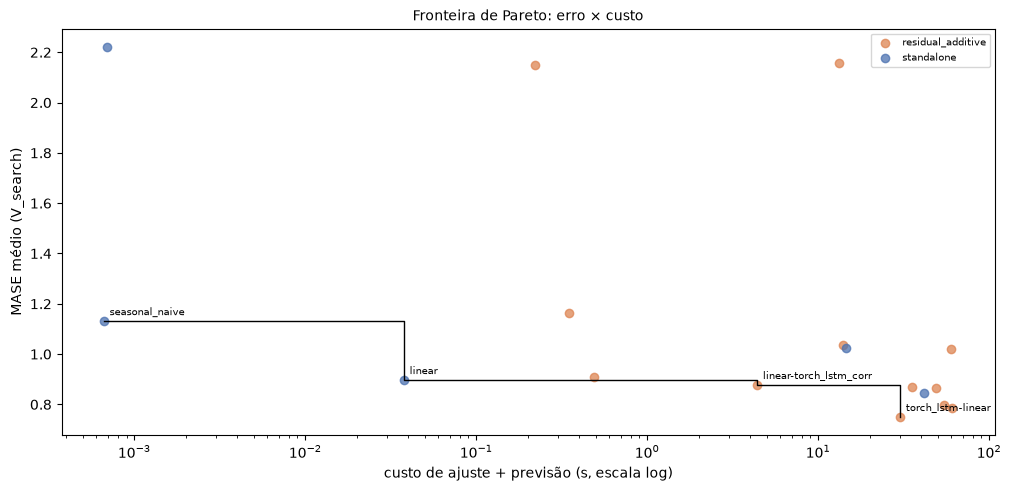

In [10]:
result.plot("pareto")

## 6. Ajuste de hiperparâmetros de uma rede

O espaço pode vir na registração (`tuning_space=`) ou na chamada. Só `V_search` é usado.

In [11]:
tuned, tuner = exp.tune_model(
    "torch_gru",
    n_trials=6,
    search_space={"hidden": [8, 16, 32], "lags": (7, 28), "learning_rate": (0.0005, 0.005)},
    return_tuner=True,
)
print(tuner.sampler, "| melhor:", tuner.best.label)
tuner.trials.sort_values("score").head()

optuna | melhor: torch_gru(hidden=8, lags=9, learning_rate=0.003557590979172391)


,candidate_id,label,score,coverage,hidden,lags,learning_rate
trial,,,,,,,
4,53c56729e16e591a36e04ae939f992de121fd4772947af...,"torch_gru(hidden=8, lags=9, learning_rate=0.00...",0.713400,1.0,8.0,9.0,0.003558
0,27400549d356a9d190e4da7514c98823d5307a82357247...,torch_gru,0.747451,1.0,NaN,NaN,NaN
2,bdbfa8282f9230754dae18b37e67f75dc17e3af17cd205...,"torch_gru(hidden=32, lags=26, learning_rate=0....",0.796834,1.0,32.0,26.0,0.002747
5,594f540eea20b59c0c42614a483ee8874cb7916fe5af4b...,"torch_gru(hidden=16, lags=16, learning_rate=0....",0.828583,1.0,16.0,16.0,0.004770
1,86c32327e439f4436000527ef603db66efe9a08a9fb3ed...,"torch_gru(hidden=8, lags=28, learning_rate=0.0...",0.874647,1.0,8.0,28.0,0.004689


## 7. Finalizar, avaliar uma vez, salvar e carregar

O manifesto registra as versões das bibliotecas usadas. Para carregar em outro processo, o módulo ou builder precisa ser importável (definido num `.py`, como os do zoo), não numa célula de notebook.

In [12]:
import tempfile

from autohybts import load_model, save_model

final = exp.finalize_model(exp.create_model("torch_lstm").candidate)
print(final.manifest["frameworks"])
print(exp.evaluate_external(final).metrics.round(3))
with tempfile.TemporaryDirectory() as folder:
    loaded = load_model(save_model(final, folder + "/lstm"), trusted=True)
np.allclose(loaded.predict(14)["y_pred"], final.predict(14)["y_pred"])

{'torch': '2.14.1+cu130'}
             MASE    MAE   RMSE  sMAPE
model                                 
torch_lstm  0.855  1.338  1.966   0.02


True

## 8. Versão exigida não satisfeita

`requires` segue a PEP 440, como o `pip`. Biblioteca ausente ou fora da faixa: a tentativa vira `SKIPPED`, com o motivo e o comando de instalação, e o experimento segue.

In [13]:
exp.register_model(
    "needs_future_torch", torch_model(LSTMNet), requires={"torch": ">=99"}, version="1"
)
skipped = exp.create_model("needs_future_torch")
pd.DataFrame(
    [(t.fold_id, t.status, t.reason) for t in skipped.evaluation.trials[:2]],
    columns=["origem", "status", "motivo"],
)

,origem,status,motivo
0,search-0,SKIPPED,UnsupportedCapabilityError: O modelo exige tor...
1,search-1,SKIPPED,UnsupportedCapabilityError: O modelo exige tor...


Pré-releases vêm antes da versão final (`2.2.0rc1` não satisfaz `>=2.2`), pós-releases não são iguais à final (`2.2.0.post1` não é `==2.2`; use `==2.2.*`) e rótulos locais como `+cu130` são ignorados. Uma especificação malformada é recusada já no registro.

In [14]:
from autohybts.exceptions import ConfigurationError
from autohybts.models import check_specifier

for version, specifier in [
    ("2.2.0rc1", ">=2.2"),
    ("2.3.0rc1", ">=2.2"),
    ("2.2.0.post1", "==2.2"),
    ("2.2.0.post1", "==2.2.*"),
    (torch.__version__, ">=2.2,<3"),
]:
    print(f"{version:14s} {specifier:10s} {check_specifier(version, specifier)}")

try:
    exp.register_model("bad", torch_model(LSTMNet), requires={"torch": "=>2.2"})
except ConfigurationError as error:
    print("recusado no registro:", error)

2.2.0rc1       >=2.2      False
2.3.0rc1       >=2.2      True
2.2.0.post1    ==2.2      False
2.2.0.post1    ==2.2.*    True
2.14.1+cu130   >=2.2,<3   True
recusado no registro: Especificação de versão inválida '=>2.2' (PEP 440); use por exemplo '>=2.2,<3', '~=2.2' ou '!=2.3.*'.
